### Linear Gravity Dispersion Equation

The dispersion relation for a surface gravity wave is (Crawford, 1991):

$${\omega}^2=gk(\omega)\tanh({k(\omega)H})$$

where $\omega$ is the angular frequency of the waves, $k$ is the wavenumber, $g$ is gravity acceleration, and $H$ is the water depth (Apel, 1987).

#### Solving for $k(\omega)$

Determining the $k(\omega)$ is crucial for both compliance measuring and forward modeling. To solve this non-linear transcendental eqution, several strategies can be employed:

* $kH$ >> 2.96, $tanh(kH)$ --> 1, $k={\omega}^2/g$ (deep water assumption); $kH$ << 1, $tanh(kH)\approx{kH}$, $k=\omega/\sqrt{gH}$ (shallow water assumption)

* Polynomial approximation (Mosher et al., 2021, GJI). Let $tanh(x)\approx\frac{27x}{x^2+9}$. This transforms the dispersion equation into a quartic polynomial in $k$, allowing efficient root-finding without iteration. This method has been widely adopted, including the [OBStools](https://nfsi-canada.github.io/OBStools/) for measuring compliance function.

* Numerical methods

    * Newton method (scipy.optimize.newton)

    * Brent method (scipy.optimize.root_scalar)

The last two method were suggested by ChatGPT

##### Newton method

Construct the function, 

$$f(k)=gktanh(kH)-{\omega}^2$$

Therefore, solving $k(\omega)$ reduces to finding the root of $f(k)=0$

The Newton iteration formula is given by:

$$k_{n+1}=k_n - \frac{f(k_n)}{f'(k_n)}$$

where the $f'(k_n)=g[tanh(kH) + kH sech^2(kH)$

In [8]:
from scipy.optimize import newton
import numpy as np

def dispersion_eq(k, omega, g, H):
    return g * k * np.tanh(k * H) - omega**2

def dispersion_eq_prime(k, omega, g, H):
    return g * (np.tanh(k * H) + k * H * (1 / np.cosh(k * H))**2)

def solve_k_newton(omega, H, g=9.79329):

    k0 = omega / np.sqrt(g * H)
    return newton(
        func=dispersion_eq,
        x0=k0,
        fprime=dispersion_eq_prime,
        args=(omega, g, H)
    )

In [9]:
# Brent method
from scipy.optimize import root_scalar

def solve_k_brent(omega, H, g=9.79329):
    f = lambda k: g * k * np.tanh(k * H) - omega**2
    return root_scalar(f, bracket=[1e-6, 1e2], method='brentq').root
    


In [10]:
#################################### IMPORTS ###################################

# The usual.
import numpy as np
import numpy.polynomial as poly

################################### FUNCTION ###################################

def gravd(ω, H):
  
  g = 9.79329 # gravitational accel. for oceanic contexts
  N = len(ω)

  # Deep water approximation for k.
  k_deep = ω**2 / g

  # Initialize values of k to be solved.
  k = np.zeros(len(ω))

  # The rational approximation to tanh(x) leads to a quartic polynomial in the
  # IG dispersion relation. We solve this using poly from numpy.polynomial.
  # Conveniently, the resulting polynomial always has real roots, and now we 
  # aren't restricted to considering deep and shallow cases seperately. Poly 
  # requires we break the resulting polynomial into terms of increasing order.

  a0 = -27 * ω**2 / g                   # constant terms
  a1 = np.zeros(len(ω))                 # no linear terms
  a2 = 27 * H - (9 * ω**2 * H**2)/g     # quadratic terms
  a3 = np.zeros(len(ω))                 # no cubic terms
  a4 = np.ones(len(ω)) * H**3           # quartic terms

  # Loop over angular frequencies and compute wavenumber for each.
  for i in range(len(ω)):

    # Case when ω = 0
    if ω[i] == 0:
      k[i] = 0

    # Othwerise  
    else:
      p = poly.Polynomial([a0[i], a1[i], a2[i], a3[i], a4[i]])
      solu = poly.Polynomial.roots(p)
      positive_roots = solu[solu > 0]

      # By default we get 4 complex numbers as results, so we force the
      # real roots (i.e. those with imaginary comp == 0) to be purely real
      # numbers.
      real_positive_root = positive_roots[positive_roots.imag == 0].real[0]
      k[i] = real_positive_root
  
  # For k*H >= 2.96, prefer the deep approximation.
  for j, wavenumber in enumerate(k_deep):
    if wavenumber * H > 2.96:
      k[j] = k_deep[j]
  
  return k

#### Example 0

In [11]:
f = np.linspace(0.004, 0.05, 100)
w = 2 * np.pi * f
H = 1500.0

k_newton = np.zeros_like(w)
k_brent = np.zeros_like(w)
for i, omega in enumerate(w):
    k_newton[i] = solve_k_newton(omega, H)
    k_brent[i] = solve_k_brent(omega, H)    

k_mosher = gravd(w, H)

Text(0.5, 1.0, 'Water depth = 1500.0 m')

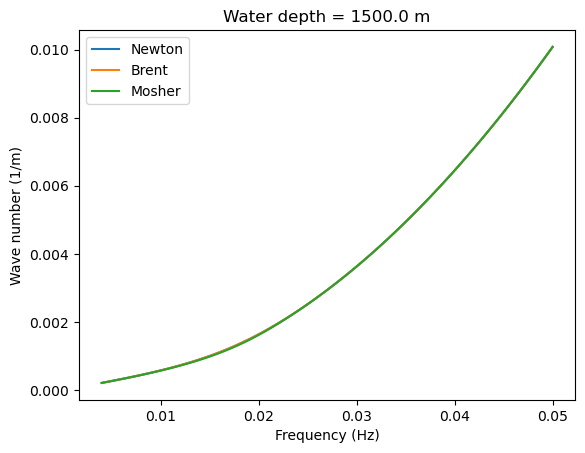

In [12]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots()
ax.plot(f, k_newton, label='Newton')
ax.plot(f, k_brent, label='Brent')
ax.plot(f, k_mosher, label='Mosher')
ax.legend()
ax.set_xlabel('Frequency (Hz)')
ax.set_ylabel('Wave number (1/m)')
ax.set_title('Water depth = %.1f m' % H)

#### Example 1

In [13]:
f = np.linspace(0.004, 0.05, 100)
w = 2 * np.pi * f
H = 300.0

k_newton = np.zeros_like(w)
k_brent = np.zeros_like(w)
for i, omega in enumerate(w):
    k_newton[i] = solve_k_newton(omega, H)
    k_brent[i] = solve_k_brent(omega, H)    

k_mosher = gravd(w, H)

Text(0.5, 1.0, 'Water depth = 300.0 m')

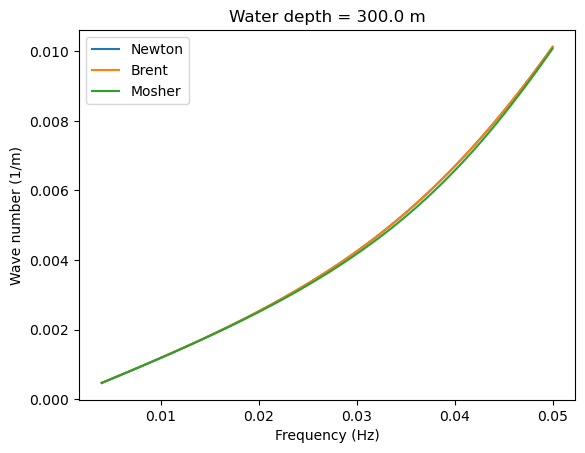

In [14]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots()
ax.plot(f, k_newton, label='Newton')
ax.plot(f, k_brent, label='Brent')
ax.plot(f, k_mosher, label='Mosher')
ax.legend()
ax.set_xlabel('Frequency (Hz)')
ax.set_ylabel('Wave number (1/m)')
ax.set_title('Water depth = %.1f m' % H)